# Chapter 39: Innovation Incentives, Creative Destruction, and Patent Races

This notebook reruns four worked examples from the chapter: rent dissipation in a patent race, preemption by an incumbent, Arrow's replacement effect and effort in a prize contest. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def equal_share_payoff(V, n, F):
    """patent-race-rent-dissipation: expected net payoff V/n - F of each of n equally likely
    entrants. Book (ch039): 90 - 20 = 70; 90/4 - 20 = 2.5; 90/5 - 20 = -2."""
    return float(V) / n - float(F)


def race_entry_count(prize, cost, n_max=50):
    """patent-race-rent-dissipation: largest n with prize/n - cost >= 0 (an entrant that exactly
    breaks even is counted). Book (ch039): prize 90, cost 20 gives 4; prize 60 gives 3 at break even."""
    n = 0
    while n < n_max and prize / (n + 1) - cost >= -1e-9:
        n += 1
    return n


def race_investment(prob_gain, prize, cost):
    """patent-race-preemption: expected benefit of a program that adds prob_gain to the chance of
    winning prize, compared with its cost. Returns {"benefit", "net", "buy", "tie"}.
    Book (ch039): 0.20(75) = 15 > 12 buys; 0.20(55) = 11 < 12 and 0.20(40) = 8 < 12 do not."""
    benefit = float(prob_gain) * float(prize)
    net = benefit - float(cost)
    tie = abs(net) < 1e-9
    return {"benefit": benefit, "net": 0.0 if tie else net, "buy": net > 1e-9, "tie": tie}


def linear_monopoly_profit(a, c):
    """arrow-replacement-effect: P = a - Q with unit cost c; Q = (a - c)/2, P = (a + c)/2,
    profit (P - c)Q. Book (ch039): c = 60 gives 20, 80, 400; c = 20 gives 40, 60, 1,600."""
    q = (a - c) / 2.0
    p = a - q
    return {"q": q, "p": p, "profit": (p - c) * q}


def replacement_gain(new_profit, old_profit):
    """arrow-replacement-effect: an incumbent's gain from adopting is new profit minus the profit it
    already earns. Book (ch039): 1,600 - 400 = 1,200; after erosion 1,600 - 100 = 1,500."""
    return float(new_profit) - float(old_profit)


def tullock_effort(V, n, r=1.0, c=1.0):
    """prize-incentives-contest: e* = rV(n - 1)/(c n^2); payoff V/n - c e*; aggregate n e*.
    Book (ch039): V 100, n 4 gives 18.75, 6.25, 75; n 2 gives 25, 25, 50; V 200 gives 37.5, 150."""
    e = r * V * (n - 1) / (c * n * n)
    return {"effort": e, "payoff": V / n - c * e, "aggregate": n * e}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(equal_share_payoff=equal_share_payoff, race_entry_count=race_entry_count, race_investment=race_investment, linear_monopoly_profit=linear_monopoly_profit, replacement_gain=replacement_gain)


games = SimpleNamespace(tullock_effort=tullock_effort)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'patent-race-rent-dissipation': {'prize': 90,
                                  'cost': 20,
                                  'one_lab': 70,
                                  'two_each': 25,
                                  'two_spend': 40,
                                  'n': 4,
                                  'each': 2.5,
                                  'spend': 80,
                                  'rent_left': 10,
                                  'fifth': -2,
                                  'prize_low': 60,
                                  'low_two_each': 10,
                                  'low_n': 3},
 'patent-race-preemption': {'win': 100,
                            'keep': 25,
                            'P_I': 75,
                            'entrant_prize': 55,
                            'gain': 0.2,
                            'cost': 12,
                            'inc_benefit': 15,
                            'ent_benefit': 11,
                            'keep_licensed': 60,
                            'P_I_licensed': 40,
                            'inc_benefit_licensed': 8},
 'arrow-replacement-effect': {'a': 100,
                              'c0': 60,
                              'c1': 20,
                              'q0': 20,
                              'p0': 80,
                              'old_profit': 400,
                              'q1': 40,
                              'p1': 60,
                              'new_profit': 1600,
                              'gain': 1200,
                              'eli_rent': 1600,
                              'outlay': 1400,
                              'eroded_old': 100,
                              'eroded_gain': 1500},
 'prize-incentives-contest': {'V': 100,
                              'n': 4,
                              'r': 1,
                              'c': 1,
                              'effort': 18.75,
                              'payoff': 6.25,
                              'aggregate': 75,
                              'V2': 200,
                              'effort_V2': 37.5,
                              'aggregate_V2': 150,
                              'effort_n2': 25,
                              'payoff_n2': 25,
                              'aggregate_n2': 50},
 'constructed': {'patent-race-rent-dissipation': {'prize': [120], 'cost': [15]},
                 'patent-race-preemption': {'keep': [40], 'cost': [10]},
                 'arrow-replacement-effect': {'old_profit': [250], 'outlay': [1000, 1700]},
                 'prize-incentives-contest': {'n': [3, 5]}}}


def trim(x, digits=2):
    """Number with trailing zeros removed: 18.75 stays, 25.00 -> 25, 0.20 -> 0.2."""
    text = num(x, digits)
    return text.rstrip("0").rstrip(".") if "." in text else text


def entry_picture(prize=90, cost=20):
    n = industrial.race_entry_count(prize, cost)
    each = industrial.equal_share_payoff(prize, n, cost)
    nxt = industrial.equal_share_payoff(prize, n + 1, cost)
    spend = n * cost
    rent = prize - spend
    ns = np.arange(1, 9)
    pays = [industrial.equal_share_payoff(prize, k, cost) for k in ns]
    fig, ax = new_figure()
    cols = [PALETTE["teal"] if k <= n else PALETTE["light"] for k in ns]
    ax.bar(ns, pays, color=cols, width=0.6)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    right = n >= 6
    mark(ax, n, each, f"n = {n}: {trim(each)} each", col="ink", dx=-8 if right else 8, dy=8,
         ha="right" if right else "left")
    ax.set_xticks(ns)
    ax.set_xlim(0.4, 8.6)
    ax.set_ylim(-15, 112)
    ax.set_xlabel("Number of equally likely labs n")
    ax.set_ylabel("Expected net payoff per lab V/n - F")
    even = abs(each) < 1e-9
    metrics = {"Labs that enter": str(n), "Payoff per entrant": trim(each),
               f"Payoff of lab {n + 1}": trim(nxt), "Total entry spending": num(spend, 0),
               "Rent left after entry costs": num(rent, 0)}
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    tail = (f" The {n}{suffix} lab exactly breaks even, so entry stops there." if even else "")
    interp = (f"With {plural(n, 'lab')}, each expects {num(prize, 0)} / {n} - {num(cost, 0)} = {trim(each)}, while "
              f"lab {n + 1} would expect {num(prize, 0)} / {n + 1} - {num(cost, 0)} = {trim(nxt)} and stays out.{tail} "
              f"Together the entrants spend {n} x {num(cost, 0)} = {num(spend, 0)} chasing a prize of {num(prize, 0)}, "
              f"leaving {num(prize, 0)} - {num(spend, 0)} = {num(rent, 0)}.")
    steps = [f"n = {n}: {num(prize, 0)} / {n} - {num(cost, 0)} = {trim(each)}",
             f"n = {n + 1}: {num(prize, 0)} / {n + 1} - {num(cost, 0)} = {trim(nxt)}, below zero",
             f"Spending = {n} x {num(cost, 0)} = {num(spend, 0)}",
             f"Rent left = {num(prize, 0)} - {num(spend, 0)} = {num(rent, 0)}"]
    alt = (f"Bars of expected net payoff per lab for 1 to 8 labs with prize {num(prize, 0)} and entry cost "
           f"{num(cost, 0)}. Payoffs stay at or above zero up to {n} labs, which spend {num(spend, 0)} in total.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def preempt_picture(keep=25, cost=12):
    bv = BV["patent-race-preemption"]
    gain, win, ent_prize = bv["gain"], bv["win"], bv["entrant_prize"]
    p_i = win - keep
    inc = industrial.race_investment(gain, p_i, cost)
    ent = industrial.race_investment(gain, ent_prize, cost)

    def word(r):
        return "Indifferent (tie)" if r["tie"] else ("Buys" if r["buy"] else "Declines")

    fig, ax = new_figure()
    bar_compare(ax, ["Incumbent", "Entrant"], [inc["benefit"], ent["benefit"]], colors=["navy", "gold"],
                value_labels=[f"0.2 x {num(p_i, 0)} = {trim(inc['benefit'])}", f"0.2 x {ent_prize} = {trim(ent['benefit'])}"],
                ylabel="Expected benefit of the program", xlabel="Firm")
    hline(ax, cost, f"program cost {cost}", col="terracotta", x_frac=0.40)
    ax.set_ylim(0, 19)
    metrics = {"Incumbent prize P_I": num(p_i, 0), "Incumbent benefit": trim(inc["benefit"]),
               "Entrant benefit": trim(ent["benefit"]), "Program cost": str(cost),
               "Incumbent": word(inc), "Entrant": word(ent)}

    def sentence(name, b):
        if b["tie"]:
            return f"the {name} is exactly indifferent"
        return f"the {name} {'buys' if b['buy'] else 'declines'}"
    rel_i = "=" if inc["tie"] else (">" if inc["buy"] else "<")
    rel_e = "=" if ent["tie"] else (">" if ent["buy"] else "<")
    interp = (f"The incumbent's prize is 100 - {keep} = {p_i}, so the program is worth 0.20 x {p_i} = "
              f"{trim(inc['benefit'])} {rel_i} {cost}; the entrant's is worth 0.20 x {ent_prize} = "
              f"{trim(ent['benefit'])} {rel_e} {cost}. So {sentence('incumbent', inc)} and "
              f"{sentence('entrant', ent)}.")
    steps = [f"P_I = 100 - {keep} = {p_i}", f"Incumbent: 0.20 x {p_i} = {trim(inc['benefit'])} {rel_i} {cost}",
             f"Entrant: 0.20 x {ent_prize} = {trim(ent['benefit'])} {rel_e} {cost}"]
    alt = (f"Two bars: the incumbent's expected benefit {trim(inc['benefit'])} and the entrant's "
           f"{trim(ent['benefit'])}, against a program cost line at {cost}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def replacement_picture(old=400, outlay=1_400):
    new = industrial.linear_monopoly_profit(100, 20)
    maya = industrial.replacement_gain(new["profit"], old)
    eli = (60 - 20) * 40
    m_go, e_go = maya > outlay, eli > outlay
    fig, ax = new_figure()
    bar_compare(ax, ["Maya (incumbent)", "Eli (entrant)"], [maya, eli], colors=["navy", "gold"],
                value_labels=[f"1,600 - {num(old, 0)} = {num(maya, 0)}", f"{num(eli, 0)}"],
                ylabel="Gain from the new process ($)", xlabel="Firm")
    hline(ax, outlay, f"outlay {num(outlay, 0)}", col="terracotta", x_frac=0.40)
    ax.set_ylim(0, 2_000)
    who = [n for n, g in (("Maya", m_go), ("Eli", e_go)) if g]
    verdict = (f"{join_and(who)} {'invests' if len(who) == 1 else 'invest'}" if who else "Nobody invests")
    metrics = {"Maya's old profit": num(old, 0), "Maya's gain": num(maya, 0), "Eli's rent": num(eli, 0),
               "Outlay": num(outlay, 0), "Who invests": verdict}
    interp = (f"With cost 20 Maya produces (100 - 20) / 2 = 40 at price 60 and earns (60 - 20) x 40 = 1,600, so her "
              f"gain is 1,600 - {num(old, 0)} = {num(maya, 0)}, {'above' if m_go else 'below'} the outlay of "
              f"{num(outlay, 0)}. Eli has no old profit to replace: his rent is (60 - 20) x 40 = {num(eli, 0)}, "
              f"{'above' if e_go else 'below'} the outlay. {verdict}.")
    steps = ["Q_M(20) = (100 - 20) / 2 = 40, price 60", "Maya's new profit = (60 - 20) x 40 = 1,600",
             f"Maya's gain = 1,600 - {num(old, 0)} = {num(maya, 0)} vs {num(outlay, 0)}",
             f"Eli's rent = (60 - 20) x 40 = {num(eli, 0)} vs {num(outlay, 0)}"]
    alt = (f"Two bars: Maya's gain {num(maya, 0)} and Eli's rent {num(eli, 0)}, against the development outlay "
           f"{num(outlay, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def contest_picture(v=100, n=4):
    r = games.tullock_effort(v, n)
    ns = np.arange(2, 6)
    fig, ax = new_figure()
    ax.plot(ns, [games.tullock_effort(v, k)["effort"] for k in ns], color=PALETTE["teal"], marker="o",
            linewidth=2.2, label="effort per team e*")
    ax.plot(ns, [games.tullock_effort(v, k)["aggregate"] for k in ns], color=PALETTE["navy"], marker="o",
            linewidth=2.2, label="aggregate effort n e*")
    hline(ax, v, f"prize {v}", col="gold", x_frac=0.02)
    side = {"dx": -8, "ha": "right"} if n == 5 else {"dx": 8, "ha": "left"}
    mark(ax, n, r["effort"], f"{trim(r['effort'])}", col="teal", dy=8 if r["effort"] < 20 else -10,
         va="bottom" if r["effort"] < 20 else "top", **side)
    mark(ax, n, r["aggregate"], f"{trim(r['aggregate'])}", col="navy", dy=8, va="bottom", **side)
    ax.legend(loc="center right", frameon=False)
    ax.set_xticks(ns)
    ax.set_xlim(1.7, 5.6)
    ax.set_ylim(0, 230)
    ax.set_xlabel("Number of teams n")
    ax.set_ylabel("Effort")
    metrics = {"Effort per team e*": trim(r["effort"]), "Expected prize per team": trim(v / n),
               "Expected payoff per team": trim(r["payoff"]), "Aggregate effort": trim(r["aggregate"])}
    interp = (f"e* = {v} x ({n} - 1) / {n}^2 = {v * (n - 1)} / {n * n} = {trim(r['effort'])}. Each team expects "
              f"{v} / {n} = {trim(v / n)} of the prize, so its payoff is {trim(v / n)} - {trim(r['effort'])} = "
              f"{trim(r['payoff'])}. All {n} teams together spend {n} x {trim(r['effort'])} = {trim(r['aggregate'])} "
              f"of effort for one prize of {v}.")
    steps = [f"e* = {v} x {n - 1} / {n * n} = {trim(r['effort'])}",
             f"Expected prize = {v} / {n} = {trim(v / n)}",
             f"Payoff = {trim(v / n)} - {trim(r['effort'])} = {trim(r['payoff'])}",
             f"Aggregate = {n} x {trim(r['effort'])} = {trim(r['aggregate'])}"]
    alt = (f"Effort per team and aggregate effort against the number of teams for a prize of {v}. With {n} teams "
           f"each spends {trim(r['effort'])} and together {trim(r['aggregate'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Patent-race rent dissipation: how many labs enter?

The prize is 90 and entry costs 20. One lab nets

$$90-20=70.$$

Four equal entrants each expect

$$\frac{90}{4}-20=2.5.$$

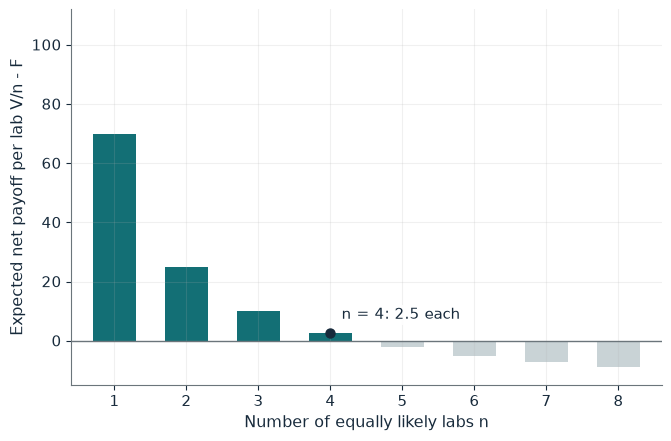

Labs that enter              4
Payoff per entrant           2.5
Payoff of lab 5              -2
Total entry spending         80
Rent left after entry costs  10

Worked steps:
  1. n = 4: 90 / 4 - 20 = 2.5
  2. n = 5: 90 / 5 - 20 = -2, below zero
  3. Spending = 4 x 20 = 80
  4. Rent left = 90 - 80 = 10

With 4 labs, each expects 90 / 4 - 20 = 2.5, while lab 5 would expect 90 / 5 - 20 = -2 and stays out. Together the entrants spend 4 x 20 = 80 chasing a prize of 90, leaving 90 - 80 = 10.


In [2]:
show(entry_picture(prize=90, cost=20))

Change one input, `prize`, and hold the others at the book's values:

In [3]:
sweep(entry_picture, 'prize', [60, 90, 120], {'cost': 20}, ['Labs that enter', 'Total entry spending', 'Rent left after entry costs'])

prize | Labs that enter | Total entry spending | Rent left after entry costs
60 | 3 | 60 | 0
90 | 4 | 80 | 10
120 | 6 | 120 | 0


Four labs enter, spend 80 and leave 10 of the 90 prize; a fifth would expect -2. With a prize of 60 the third lab only breaks even, and entry spending equals the whole prize.

## 2. Patent-race preemption: why incumbents race harder

The incumbent keeps 25 if the entrant wins, so

$$P_I=100-25=75.$$

A program adds 0.20 to the chance of winning at a cost of 12:

$$0.20(75)=15>12.$$

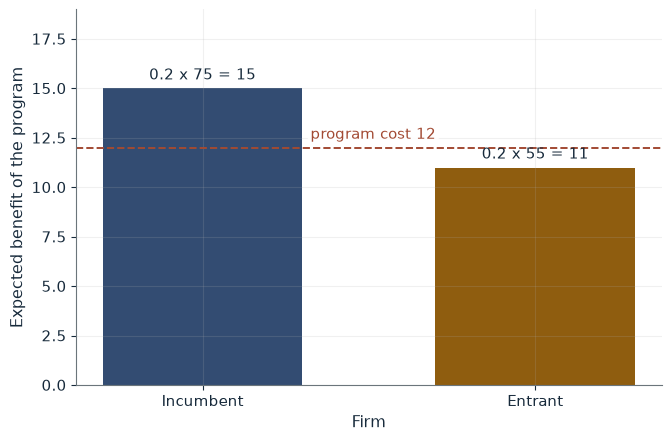

Incumbent prize P_I  75
Incumbent benefit    15
Entrant benefit      11
Program cost         12
Incumbent            Buys
Entrant              Declines

Worked steps:
  1. P_I = 100 - 25 = 75
  2. Incumbent: 0.20 x 75 = 15 > 12
  3. Entrant: 0.20 x 55 = 11 < 12

The incumbent's prize is 100 - 25 = 75, so the program is worth 0.20 x 75 = 15 > 12; the entrant's is worth 0.20 x 55 = 11 < 12. So the incumbent buys and the entrant declines.


In [4]:
show(preempt_picture(keep=25, cost=12))

Change one input, `keep`, and hold the others at the book's values:

In [5]:
sweep(preempt_picture, 'keep', [25, 40, 60], {'cost': 12}, ['Incumbent benefit', 'Incumbent', 'Entrant'])

keep | Incumbent benefit | Incumbent | Entrant
25 | 15 | Buys | Declines
40 | 12 | Indifferent (tie) | Declines
60 | 8 | Declines | Declines


The entrant's benefit is 0.20(55) = 11 < 12, so only the incumbent buys. If licensing lets it keep 60, $0.20(40)=8<12$ and it declines; keeping 40 leaves it exactly indifferent.

## 3. Arrow replacement effect: who gains more from the same invention?

Demand is $P=100-Q$ and

$$Q_M(c)=\frac{100-c}{2}.$$

At cost 60 Maya earns

$$(80-60)20=\$400.$$

At cost 20 she would earn \$1,600, a gain of

$$1{,}600-400=\$1{,}200.$$

Entrant Eli's rent is

$$(60-20)40=\$1{,}600.$$

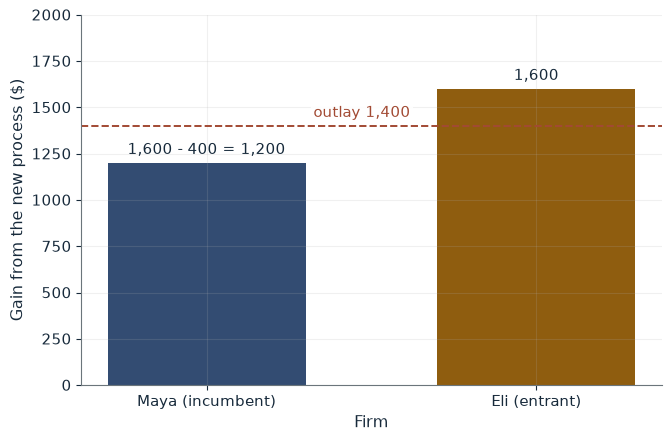

Maya's old profit  400
Maya's gain        1,200
Eli's rent         1,600
Outlay             1,400
Who invests        Eli invests

Worked steps:
  1. Q_M(20) = (100 - 20) / 2 = 40, price 60
  2. Maya's new profit = (60 - 20) x 40 = 1,600
  3. Maya's gain = 1,600 - 400 = 1,200 vs 1,400
  4. Eli's rent = (60 - 20) x 40 = 1,600 vs 1,400

With cost 20 Maya produces (100 - 20) / 2 = 40 at price 60 and earns (60 - 20) x 40 = 1,600, so her gain is 1,600 - 400 = 1,200, below the outlay of 1,400. Eli has no old profit to replace: his rent is (60 - 20) x 40 = 1,600, above the outlay. Eli invests.


In [6]:
show(replacement_picture(old=400, outlay=1_400))

Change one input, `old`, and hold the others at the book's values:

In [7]:
sweep(replacement_picture, 'old', [400, 250, 100], {'outlay': 1400}, ["Maya's gain", 'Who invests'])

old | Maya's gain | Who invests
400 | 1,200 | Eli invests
250 | 1,350 | Eli invests
100 | 1,500 | Maya and Eli invest


With an outlay of \$1,400 only Eli invests. Once competition erodes Maya's old profit to \$100, her gain is \$1,500 and she invests too: the invention did not change, the profit it replaces did.

## 4. Prize incentives: prize size and number of contestants

In a symmetric Tullock contest

$$e^*=\frac{rV(n-1)}{cn^2}.$$

With $V=100$, $r=c=1$ and four teams,

$$e^*=\frac{100(4-1)}{4^2}=18.75.$$

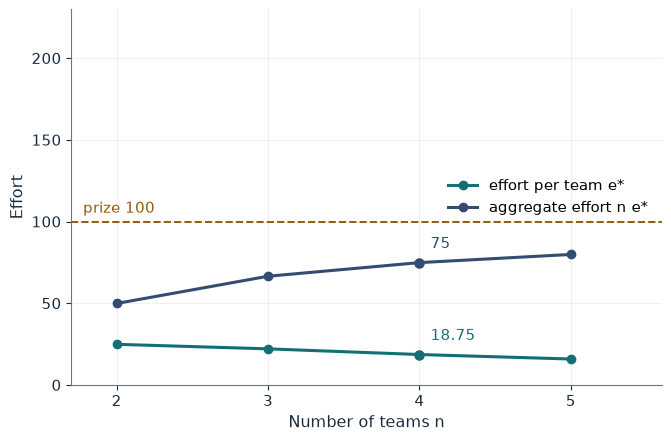

Effort per team e*        18.75
Expected prize per team   25
Expected payoff per team  6.25
Aggregate effort          75

Worked steps:
  1. e* = 100 x 3 / 16 = 18.75
  2. Expected prize = 100 / 4 = 25
  3. Payoff = 25 - 18.75 = 6.25
  4. Aggregate = 4 x 18.75 = 75

e* = 100 x (4 - 1) / 4^2 = 300 / 16 = 18.75. Each team expects 100 / 4 = 25 of the prize, so its payoff is 25 - 18.75 = 6.25. All 4 teams together spend 4 x 18.75 = 75 of effort for one prize of 100.


In [8]:
show(contest_picture(v=100, n=4))

Change one input, `n`, and hold the others at the book's values:

In [9]:
sweep(contest_picture, 'n', [2, 3, 4, 5], {'v': 100}, ['Effort per team e*', 'Expected payoff per team', 'Aggregate effort'])

n | Effort per team e* | Expected payoff per team | Aggregate effort
2 | 25 | 25 | 50
3 | 22.22 | 11.11 | 66.67
4 | 18.75 | 6.25 | 75
5 | 16 | 4 | 80


Each team expects 25 of the prize and keeps 6.25 after its effort; together the four spend 75. With two teams, $e^*=\frac{100(2-1)}{2^2}=25$ and aggregate effort falls to 50. Doubling the prize doubles every effort figure.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

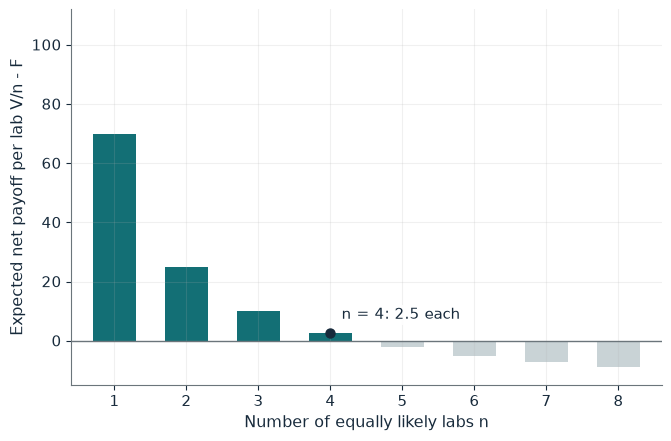

Labs that enter              4
Payoff per entrant           2.5
Payoff of lab 5              -2
Total entry spending         80
Rent left after entry costs  10

Worked steps:
  1. n = 4: 90 / 4 - 20 = 2.5
  2. n = 5: 90 / 5 - 20 = -2, below zero
  3. Spending = 4 x 20 = 80
  4. Rent left = 90 - 80 = 10

With 4 labs, each expects 90 / 4 - 20 = 2.5, while lab 5 would expect 90 / 5 - 20 = -2 and stays out. Together the entrants spend 4 x 20 = 80 chasing a prize of 90, leaving 90 - 80 = 10.


In [10]:
show(entry_picture(prize=90, cost=20))

## Practice

**1.** With a prize of 120 and an entry cost of 20, how many labs enter and how much rent survives?

<details><summary>Answer</summary>

120 / 6 - 20 = 0 and 120 / 7 - 20 < 0, so 6 labs enter, spend 120 and leave no rent.

</details>

**2.** With a kept value of 40 and a program cost of 10, who buys the program?

<details><summary>Answer</summary>

Incumbent 0.20(60) = 12 > 10 and entrant 0.20(55) = 11 > 10: both buy.

</details>

**3.** With V = 100 and n = 5, what is aggregate effort?

<details><summary>Answer</summary>

e* = 100 x 4 / 25 = 16, so aggregate effort is 5 x 16 = 80.

</details>